# Predictive Customer Analytics

## Objective

Predict whether an existing customer will make a purchase within the next 30 days.

### Approach

1. Load cleaned transaction data
2. Create customer behavioral features from historical purchases
3. Create a 30-day future-purchase target
4. Train and compare multiple ML models
5. Evaluate model performance
6. Identify the most important predictive features

### Models

- Logistic Regression
- Random Forest
- XGBoost

### Evaluation

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

In [1]:
# Cell 2: Create customer prediction dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
from xgboost import XGBClassifier
import joblib

# Load cleaned data
df = pd.read_csv("../data/processed/online_retail_clean.csv")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Only identifiable customers
df = df.dropna(subset=["Customer ID"]).copy()
df["Customer ID"] = df["Customer ID"].astype(int)

# Prediction cutoff
cutoff_date = pd.Timestamp("2011-10-01")
prediction_end = cutoff_date + pd.Timedelta(days=30)

# Historical transactions
history = df[df["InvoiceDate"] < cutoff_date].copy()

# Future transactions used only to create the target
future = df[
    (df["InvoiceDate"] >= cutoff_date) &
    (df["InvoiceDate"] < prediction_end)
].copy()

# Customer-level historical features
features = history.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (cutoff_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    ActiveDays=("InvoiceDate", lambda x: x.dt.date.nunique())
).reset_index()

# Target: purchased during next 30 days
future_customers = set(future["Customer ID"].unique())

features["Purchased_Next_30_Days"] = (
    features["Customer ID"].isin(future_customers).astype(int)
)

print("Prediction dataset shape:", features.shape)
print("\nTarget distribution:")
print(features["Purchased_Next_30_Days"].value_counts())

features.head()

/var/folders/sj/rw1skm1j5hg2bbbhk0sytpq40000gn/T/ipykernel_2982/839763091.py:24: DtypeWarning: Columns (0: Invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/processed/online_retail_clean.csv")


Prediction dataset shape: (5438, 8)

Target distribution:
Purchased_Next_30_Days
0    4328
1    1110
Name: count, dtype: int64


,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,ActiveDays,Purchased_Next_30_Days
0,12346,255,12,77556.46,74285,27,8,0
1,12347,59,6,3402.39,2099,107,6,0
2,12348,5,5,2019.40,2714,25,5,0
3,12349,337,3,2671.14,993,90,3,0
4,12350,240,1,334.40,197,17,1,0


In [2]:
# Cell 3: Train and compare ML models

X = features.drop(
    columns=["Customer ID", "Purchased_Next_30_Days"]
)

y = features["Purchased_Next_30_Days"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        )
    })

results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC",
    ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,XGBoost,0.829963,0.776119,0.234234,0.359862,0.777745
0,Logistic Regression,0.826287,0.789474,0.202703,0.322581,0.772023
1,Random Forest,0.793199,0.492754,0.459459,0.475524,0.755737


BEST MODEL: XGBoost

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.98      0.90       866
           1       0.78      0.23      0.36       222

    accuracy                           0.83      1088
   macro avg       0.80      0.61      0.63      1088
weighted avg       0.82      0.83      0.79      1088

ROC-AUC: 0.7777

Feature Importance:


,Feature,Importance
5,ActiveDays,0.251859
0,Recency,0.231674
1,Frequency,0.184415
4,UniqueProducts,0.114020
2,Monetary,0.112208
3,TotalQuantity,0.105824


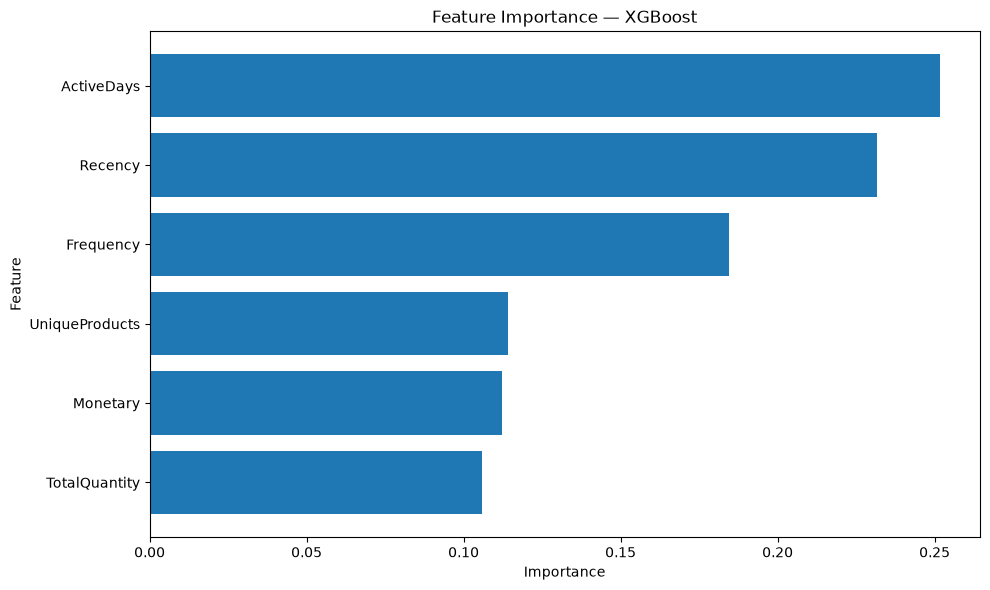

In [3]:
# Cell 4: Evaluate and interpret the best model

best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

predictions = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)[:, 1]

print("=" * 60)
print(f"BEST MODEL: {best_model_name}")
print("=" * 60)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        predictions,
        zero_division=0
    )
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, probabilities), 4)
)

# Feature importance
if best_model_name == "XGBoost":
    importance = best_model.feature_importances_

elif best_model_name == "Random Forest":
    importance = best_model.feature_importances_

else:
    importance = np.abs(
        best_model.named_steps["model"].coef_[0]
    )

feature_importance = (
    pd.DataFrame({
        "Feature": X.columns,
        "Importance": importance
    })
    .sort_values("Importance", ascending=False)
)

print("\nFeature Importance:")
display(feature_importance)

plt.figure(figsize=(10, 6))

top_features = feature_importance.head(10).sort_values(
    "Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title(f"Feature Importance — {best_model_name}")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [5]:
# Cell 5: Save model + prediction dataset

import os
import joblib

os.makedirs("../models", exist_ok=True)

model_path = "../models/customer_purchase_predictor.joblib"

joblib.dump(best_model, model_path)

features.to_csv(
    "../data/processed/customer_prediction_data.csv",
    index=False
)

print("=" * 60)
print("PREDICTIVE ANALYTICS COMPLETED")
print("=" * 60)

print(f"\nBest model: {best_model_name}")
print(f"Model saved: {model_path}")
print("Prediction dataset saved successfully.")

PREDICTIVE ANALYTICS COMPLETED

Best model: XGBoost
Model saved: ../models/customer_purchase_predictor.joblib
Prediction dataset saved successfully.
